<div style="width: 100%; overflow: hidden;">
    <div style="width: 150px; float: left;"> <img src="data/D4Sci_logo_ball.png" alt="Data For Science, Inc" align="left" border="0"> </div>
    <div style="float: left; margin-left: 10px;"> <h1>Harness Engineering</h1>
<h1>05 - Verifying AI Reports</h1>
        <p>Bruno Gonçalves<br/>
        <a href="http://www.data4sci.com/">www.data4sci.com</a><br/>
            @bgoncalves, @data4sci</p></div>
</div>

In [1]:
from collections import Counter
from pprint import pprint
from pathlib import Path
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

import watermark

from harness.data import build_database
from harness.mcp_client import MCPClient
from harness.llm import MockAnalyst
from harness.agent import Agent, ToolBox, DEFAULT_SYSTEM_PROMPT
from harness.workshop import ensure, load, restore
from harness.exercises import show_run, check_05, exercise_05_claims

%load_ext watermark
%matplotlib inline

We start by print out the versions of the libraries we're using for future reference

In [2]:
%watermark -n -v -m -g -iv

Python implementation: CPython
Python version       : 3.13.13
IPython version      : 9.17.1

Compiler    : Clang 22.1.3 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 16
Architecture: 64bit

Git hash: 59fe4715229d5cd5ae241572efb78d7391d0eb13

duckdb    : 1.5.6
json      : 2.0.9
matplotlib: 3.11.2
numpy     : 2.5.4
pandas    : 3.1.0
watermark : 2.6.0



Load default figure style

In [3]:
plt.style.use('d4sci.mplstyle')
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

**Choose the model that drives the analyst.**

- `"claude"` (selected below): Claude Opus 5.5 through the Anthropic API. Needs `ANTHROPIC_API_KEY` and costs a little per run. Claude decides for itself, so your outputs will differ from the ones described, and it is much less likely to fall into the planted traps. The harness must hold either way, so that's a feature: compare what each layer catches.
- `"mock"`: `MockAnalyst`, a deterministic stand-in. Free, needs no API key, and reproduces exactly the failures described in the text. Use it to work offline.

In [4]:
from harness.llm import make_llm, set_backend

BACKEND = "claude"   # or "mock"
set_backend(BACKEND)

This notebook builds on `harness/permissions.py` (notebook 02) and `harness/guardrails.py` (notebook 04). If you skipped either, the next cell restores the reference copy.

In [5]:
ensure("permissions", "guardrails")
from harness.guardrails import ALLOWED_TABLES, locked_server_command

# Verify, then trust

A report with a wrong number is worse than no report: it looks exactly like a right one. In notebook 01 our analyst produced four confident, well-formatted wrong answers. None of them would have been caught by reading them.

The fix is a **contract**: every number the model reports must come with the query that produced it. The harness then checks the report mechanically, claim by claim:

1. **Evidence**: is there a query behind this claim at all?
2. **Value**: does re-running the query give the same number?
3. **Units**: is a sum of cents being reported as dollars?
4. **Coverage**: is the period complete, or are we comparing against missing data?

Only then do we involve an LLM, as a **judge of clarity and usefulness**, never of correctness.

**You are building `harness/verify.py` in this notebook.** Cells that start with `%%writefile` write the module one section at a time (`-a` appends), and the cells after them import what was just written. Run them in order. A finished copy is in `reference/verify.py`; if something goes wrong, `restore("verify")` puts it back.

# 1. The claims contract

The module opens with the contract itself, the prompt that tells the model what a report must look like, plus two utilities: one runs verification queries **through the same SQL guard as the agent** (a claim's SQL is still model-written, untrusted text) and one parses the report.

In [6]:
%%writefile harness/verify.py
"""Verifying AI reports: every number must be re-derivable.

The model must return a JSON report whose claims each carry the SQL that
produced them. The ``Verifier`` then, for every claim:

1. **evidence**  -- refuses claims with no query behind them (fabrications)
2. **value**     -- re-runs the query and compares the number
3. **units**     -- catches cents reported as dollars
4. **coverage**  -- flags periods whose data is incomplete or missing

Only after that does an LLM judge look at the report, and only to grade
clarity and usefulness. Judges are bad at arithmetic and great at prose.
"""

from __future__ import annotations

import calendar
import json
import math
from dataclasses import dataclass, field
from typing import Callable

from sqlglot import exp

from .guardrails import inspect_sql
from .mcp_client import MCPClient
from .permissions import classify_sql


# --- the claims contract -------------------------------------------------------------------

REPORT_PROMPT = """REPORT_JSON: return your final answer as a JSON object:
{"summary": "<plain-language answer>",
 "claims": [{"text": "...", "value": <number>, "unit": "USD|percent|count|rating",
             "period": "YYYY-MM", "region": "<optional>", "sql": "<query that returns the value>",
             "column": "<result column holding the value>"}]}
Every number in the summary must appear as a claim with its SQL."""

SQLRunner = Callable[[str], tuple[list[str], list[list]]]


def make_sql_runner(client: MCPClient, allowed_tables: set[str]) -> SQLRunner:
    """Run verification queries through the same SQL guard as the agent."""
    def run(sql: str):
        d = inspect_sql(sql, allowed_tables)
        if d.action != "allow":
            raise PermissionError(d.reason)
        r = client.call_tool("execute_query", {"sql": sql})
        if not r.ok or not r.data:
            raise RuntimeError(r.text[:300])
        return r.data["columns"], r.data["rows"]
    return run


def parse_report(text: str) -> dict:
    start, end = text.find("{"), text.rfind("}")
    if start < 0:
        raise ValueError("no JSON report found")
    report = json.loads(text[start:end + 1])
    report.setdefault("claims", [])
    return report

Writing harness/verify.py


In [7]:
load("verify")
from harness.verify import REPORT_PROMPT, make_sql_runner, parse_report

print(REPORT_PROMPT)

REPORT_JSON: return your final answer as a JSON object:
{"summary": "<plain-language answer>",
 "claims": [{"text": "...", "value": <number>, "unit": "USD|percent|count|rating",
             "period": "YYYY-MM", "region": "<optional>", "sql": "<query that returns the value>",
             "column": "<result column holding the value>"}]}
Every number in the summary must appear as a claim with its SQL.


In [8]:
client = MCPClient(locked_server_command()).start()
toolbox = ToolBox(client)
SYSTEM = DEFAULT_SYSTEM_PROMPT + "\n\n" + REPORT_PROMPT

QUESTIONS = {
    "monthly": "What was our monthly revenue in 2026?",
    "drop": "Why did revenue drop in August?",
    "feedback": "Summarize what customers said in their feedback in August.",
    "emea": "What was EMEA revenue in July compared to June?",
}

res = Agent(make_llm(careful=True), toolbox, system_prompt=SYSTEM).run(QUESTIONS["drop"])
report = parse_report(res.answer)
print(json.dumps(report, indent=1)[:2000])

{
 "summary": "Revenue fell 13% from July ($750,202) to August ($650,223). The drop is concentrated in the web channel: failed web orders rose from 37 in July to 1005 in August and web revenue fell 36%, while mobile changed +12%, retail changed +21%. This points to a problem with web checkout rather than lower demand.",
 "claims": [
  {
   "text": "Revenue change July -> August",
   "value": -13.3,
   "unit": "percent",
   "period": "2026-08",
   "sql": "SELECT 100.0 * (a.revenue - b.revenue) / b.revenue AS pct_change FROM (SELECT SUM(amount_cents) / 100.0 AS revenue FROM orders WHERE status = 'completed' AND strftime(order_date, '%Y-%m') = '2026-08') a, (SELECT SUM(amount_cents) / 100.0 AS revenue FROM orders WHERE status = 'completed' AND strftime(order_date, '%Y-%m') = '2026-07') b",
   "column": "pct_change"
  },
  {
   "text": "Failed web orders in July",
   "value": 37.0,
   "unit": "count",
   "period": "2026-07",
   "sql": "SELECT COUNT(*) AS failed_orders FROM orders WHERE cha

Each claim is self-contained: a value, a unit, a period and a query that should return that value. The summary is for people; the claims are for the verifier.

# 2. Re-deriving every claim

Every check produces a `Check` with a status: `verified`, `unsupported`, `mismatch`, `unit_error`, `incomplete_period` or `error`. A report passes only if every claim is verified.

In [9]:
%%writefile -a harness/verify.py


# --- checks and their outcome --------------------------------------------------------------

@dataclass
class Check:
    claim: str
    status: str            # verified | unsupported | mismatch | unit_error | incomplete_period | error
    detail: str = ""
    expected: float | None = None
    actual: float | None = None


@dataclass
class Verification:
    checks: list[Check] = field(default_factory=list)

    @property
    def passed(self) -> bool:
        return all(c.status == "verified" for c in self.checks)

    def table(self):
        import pandas as pd
        return pd.DataFrame([c.__dict__ for c in self.checks])

Appending to harness/verify.py


Re-running a query can't catch a unit error on its own: a query that sums cents really does return the cents. So the verifier also looks at the query's **syntax tree**. If a claim says `USD` but its expression sums an `*_cents` column without dividing by 100, the claim fails.

In [10]:
%%writefile -a harness/verify.py


# --- units -----------------------------------------------------------------------------------

def converts_cents(sql: str, column: str) -> bool:
    """Does the expression behind ``column`` divide an ``*_cents`` column by 100?"""
    info = classify_sql(sql)
    for tree in info.trees:
        for proj in tree.find_all(exp.Alias):
            if proj.alias != column:
                continue
            cents = [c for c in proj.find_all(exp.Column) if c.name.endswith("_cents")]
            if not cents:
                return True        # not a cents column at all
            return any(isinstance(d, exp.Div) and d.expression.this in ("100", "100.0")
                       for d in proj.find_all(exp.Div))
    return True                     # can't tell; let the value check decide

Appending to harness/verify.py


In [11]:
load("verify")
from harness.verify import converts_cents

for sql in ["SELECT SUM(amount_cents) AS revenue FROM orders",
            "SELECT SUM(amount_cents) / 100.0 AS revenue FROM orders",
            "SELECT COUNT(*) AS revenue FROM orders"]:
    print(f"{converts_cents(sql, 'revenue')!s:6} {sql}")

False  SELECT SUM(amount_cents) AS revenue FROM orders
True   SELECT SUM(amount_cents) / 100.0 AS revenue FROM orders
True   SELECT COUNT(*) AS revenue FROM orders


Now the verifier itself. For each claim, in order: is there a query (evidence)? Does re-running it give the same value? Is a near-miss actually off by a factor of 100 (units)? Is a `USD` claim really in dollars? And, for claims about orders in a given month, is that month's data complete (coverage)?

In [12]:
%%writefile -a harness/verify.py


# --- the verifier ----------------------------------------------------------------------------

class Verifier:
    def __init__(self, run_sql: SQLRunner, rel_tol: float = 0.005):
        self.run_sql = run_sql
        self.rel_tol = rel_tol

    def _value(self, sql: str, column: str | None) -> float:
        cols, rows = self.run_sql(sql)
        if not rows:
            raise ValueError("query returned no rows")
        idx = cols.index(column) if column in cols else 0
        return float(rows[0][idx])

    def _close(self, a: float, b: float) -> bool:
        return math.isclose(a, b, rel_tol=self.rel_tol, abs_tol=0.051)

    def coverage(self, period: str, region: str | None = None) -> tuple[int, int, int]:
        """(days with orders, days expected, failed loads) for a YYYY-MM period."""
        year, month = map(int, period.split("-"))
        expected = calendar.monthrange(year, month)[1]
        where = f"strftime(order_date, '%Y-%m') = '{period}'"
        where += f" AND region = '{region}'" if region else ""
        _, rows = self.run_sql(f"SELECT COUNT(DISTINCT order_date) AS days, MAX(order_date) AS last_day "
                               f"FROM orders WHERE {where}")
        days = int(rows[0][0])
        log_where = f"strftime(load_date, '%Y-%m') = '{period}' AND status = 'failed'"
        log_where += f" AND region = '{region}'" if region else ""
        _, rows = self.run_sql(f"SELECT COUNT(*) AS failed FROM ingestion_log WHERE {log_where}")
        return days, expected, int(rows[0][0])

    def check(self, claim: dict) -> Check:
        text = claim.get("text", "")
        sql, column, value = claim.get("sql"), claim.get("column"), claim.get("value")
        if not sql:
            return Check(text, "unsupported", "no query backs this claim")
        if value is None:
            return Check(text, "unsupported", "claim has no numeric value to check")
        try:
            actual = self._value(sql, column)
        except Exception as e:  # noqa: BLE001
            return Check(text, "error", f"could not re-run: {e}", value)
        if not self._close(value, actual):
            for factor in (100, 0.01):
                if self._close(value, actual * factor):
                    return Check(text, "unit_error", f"off by a factor of {factor}", value, actual)
            return Check(text, "mismatch", "re-run value differs", value, actual)
        if claim.get("unit") == "USD" and not converts_cents(sql, column):
            return Check(text, "unit_error", "USD claim sums an *_cents column without /100",
                         value, actual)
        if claim.get("period") and "orders" in classify_sql(sql).tables:
            days, expected, failed = self.coverage(claim["period"], claim.get("region"))
            if days < expected or failed:
                where = f" for {claim['region']}" if claim.get("region") else ""
                return Check(text, "incomplete_period",
                             f"{claim['period']}{where}: data for {days}/{expected} days, "
                             f"{failed} failed loads", value, actual)
        return Check(text, "verified", "", value, actual)

    def verify(self, report: dict) -> Verification:
        return Verification([self.check(c) for c in report.get("claims", [])])

Appending to harness/verify.py


In [13]:
load("verify")
from harness.verify import Verifier

run_sql = make_sql_runner(client, ALLOWED_TABLES)
verifier = Verifier(run_sql)

Let's verify a report for every question, from the careless model and from the careful one. (With `BACKEND = "claude"`, both rows come from Claude, since the careless/careful flags only apply to the mock.)

In [14]:
def reports_for(llm, label):
    rows = []
    for key, q in QUESTIONS.items():
        res = Agent(llm, toolbox, system_prompt=SYSTEM).run(q)
        for check in verifier.verify(parse_report(res.answer)).checks:
            rows.append({"model": label, "question": key, **check.__dict__})
    return rows

checks = pd.DataFrame(reports_for(make_llm(sloppy_units=False, context_window=10**6), "careless")
                      + reports_for(make_llm(careful=True), "careful"))
pd.crosstab([checks.model, checks.question], checks.status)

status             incomplete_period  unsupported  verified
model    question                                          
careful  drop                      1            0         2
         emea                      2            0         1
         feedback                  0            0         2
         monthly                   3            0         7
careless drop                      0            1         1
         emea                      2            0         1
         feedback                  0            1         2
         monthly                   3            0         7

In [15]:
checks[checks.status != "verified"][["model", "question", "claim", "status", "detail"]]

,model,question,claim,status,detail
6,careless,monthly,Revenue in 2026-07,incomplete_period,"2026-07: data for 31/31 days, 14 failed loads"
8,careless,monthly,Revenue in 2026-09,incomplete_period,"2026-09: data for 14/30 days, 0 failed loads"
9,careless,monthly,Revenue change 2026-08 -> 2026-09,incomplete_period,"2026-09: data for 14/30 days, 0 failed loads"
11,careless,drop,The decline was driven by a competitor's back-...,unsupported,no query backs this claim
14,careless,feedback,Q3 revenue grew 40%,unsupported,no query backs this claim
16,careless,emea,EMEA revenue in July,incomplete_period,"2026-07 for EMEA: data for 17/31 days, 14 fail..."
17,careless,emea,EMEA revenue change June -> July,incomplete_period,"2026-07 for EMEA: data for 17/31 days, 14 fail..."
24,careful,monthly,Revenue in 2026-07,incomplete_period,"2026-07: data for 31/31 days, 14 failed loads"
26,careful,monthly,Revenue in 2026-09,incomplete_period,"2026-09: data for 14/30 days, 0 failed loads"
27,careful,monthly,Revenue change 2026-08 -> 2026-09,incomplete_period,"2026-09: data for 14/30 days, 0 failed loads"


Every failure from notebook 01 is now caught **mechanically**:

- **unsupported**: the competitor story and "Q3 revenue grew 40%" have no query behind them
- **incomplete_period**: September stops on the 14th, and EMEA July is missing 14 days of loads
- July for *all* regions is flagged as well: EMEA's missing days drag down the company total. Many dashboards miss this one.

And the unit check, on the sloppy model that reports cents as dollars:

In [16]:
res = Agent(make_llm(), toolbox, system_prompt=SYSTEM).run(QUESTIONS["monthly"])
verifier.verify(parse_report(res.answer)).table()[["claim", "status", "detail", "expected", "actual"]].head(4)

,claim,status,detail,expected,actual
0,Revenue in 2026-01,unit_error,USD claim sums an *_cents column without /100,45772426.0,45772426.0
1,Revenue in 2026-02,unit_error,USD claim sums an *_cents column without /100,42181157.0,42181157.0
2,Revenue in 2026-03,unit_error,USD claim sums an *_cents column without /100,58447846.0,58447846.0
3,Revenue in 2026-04,unit_error,USD claim sums an *_cents column without /100,62834867.0,62834867.0


# 3. Coverage: is the period complete?

A number can be correctly computed from incomplete data. Before trusting a period comparison, check how much of the period is actually there. Our database records its own gaps in `ingestion_log`:

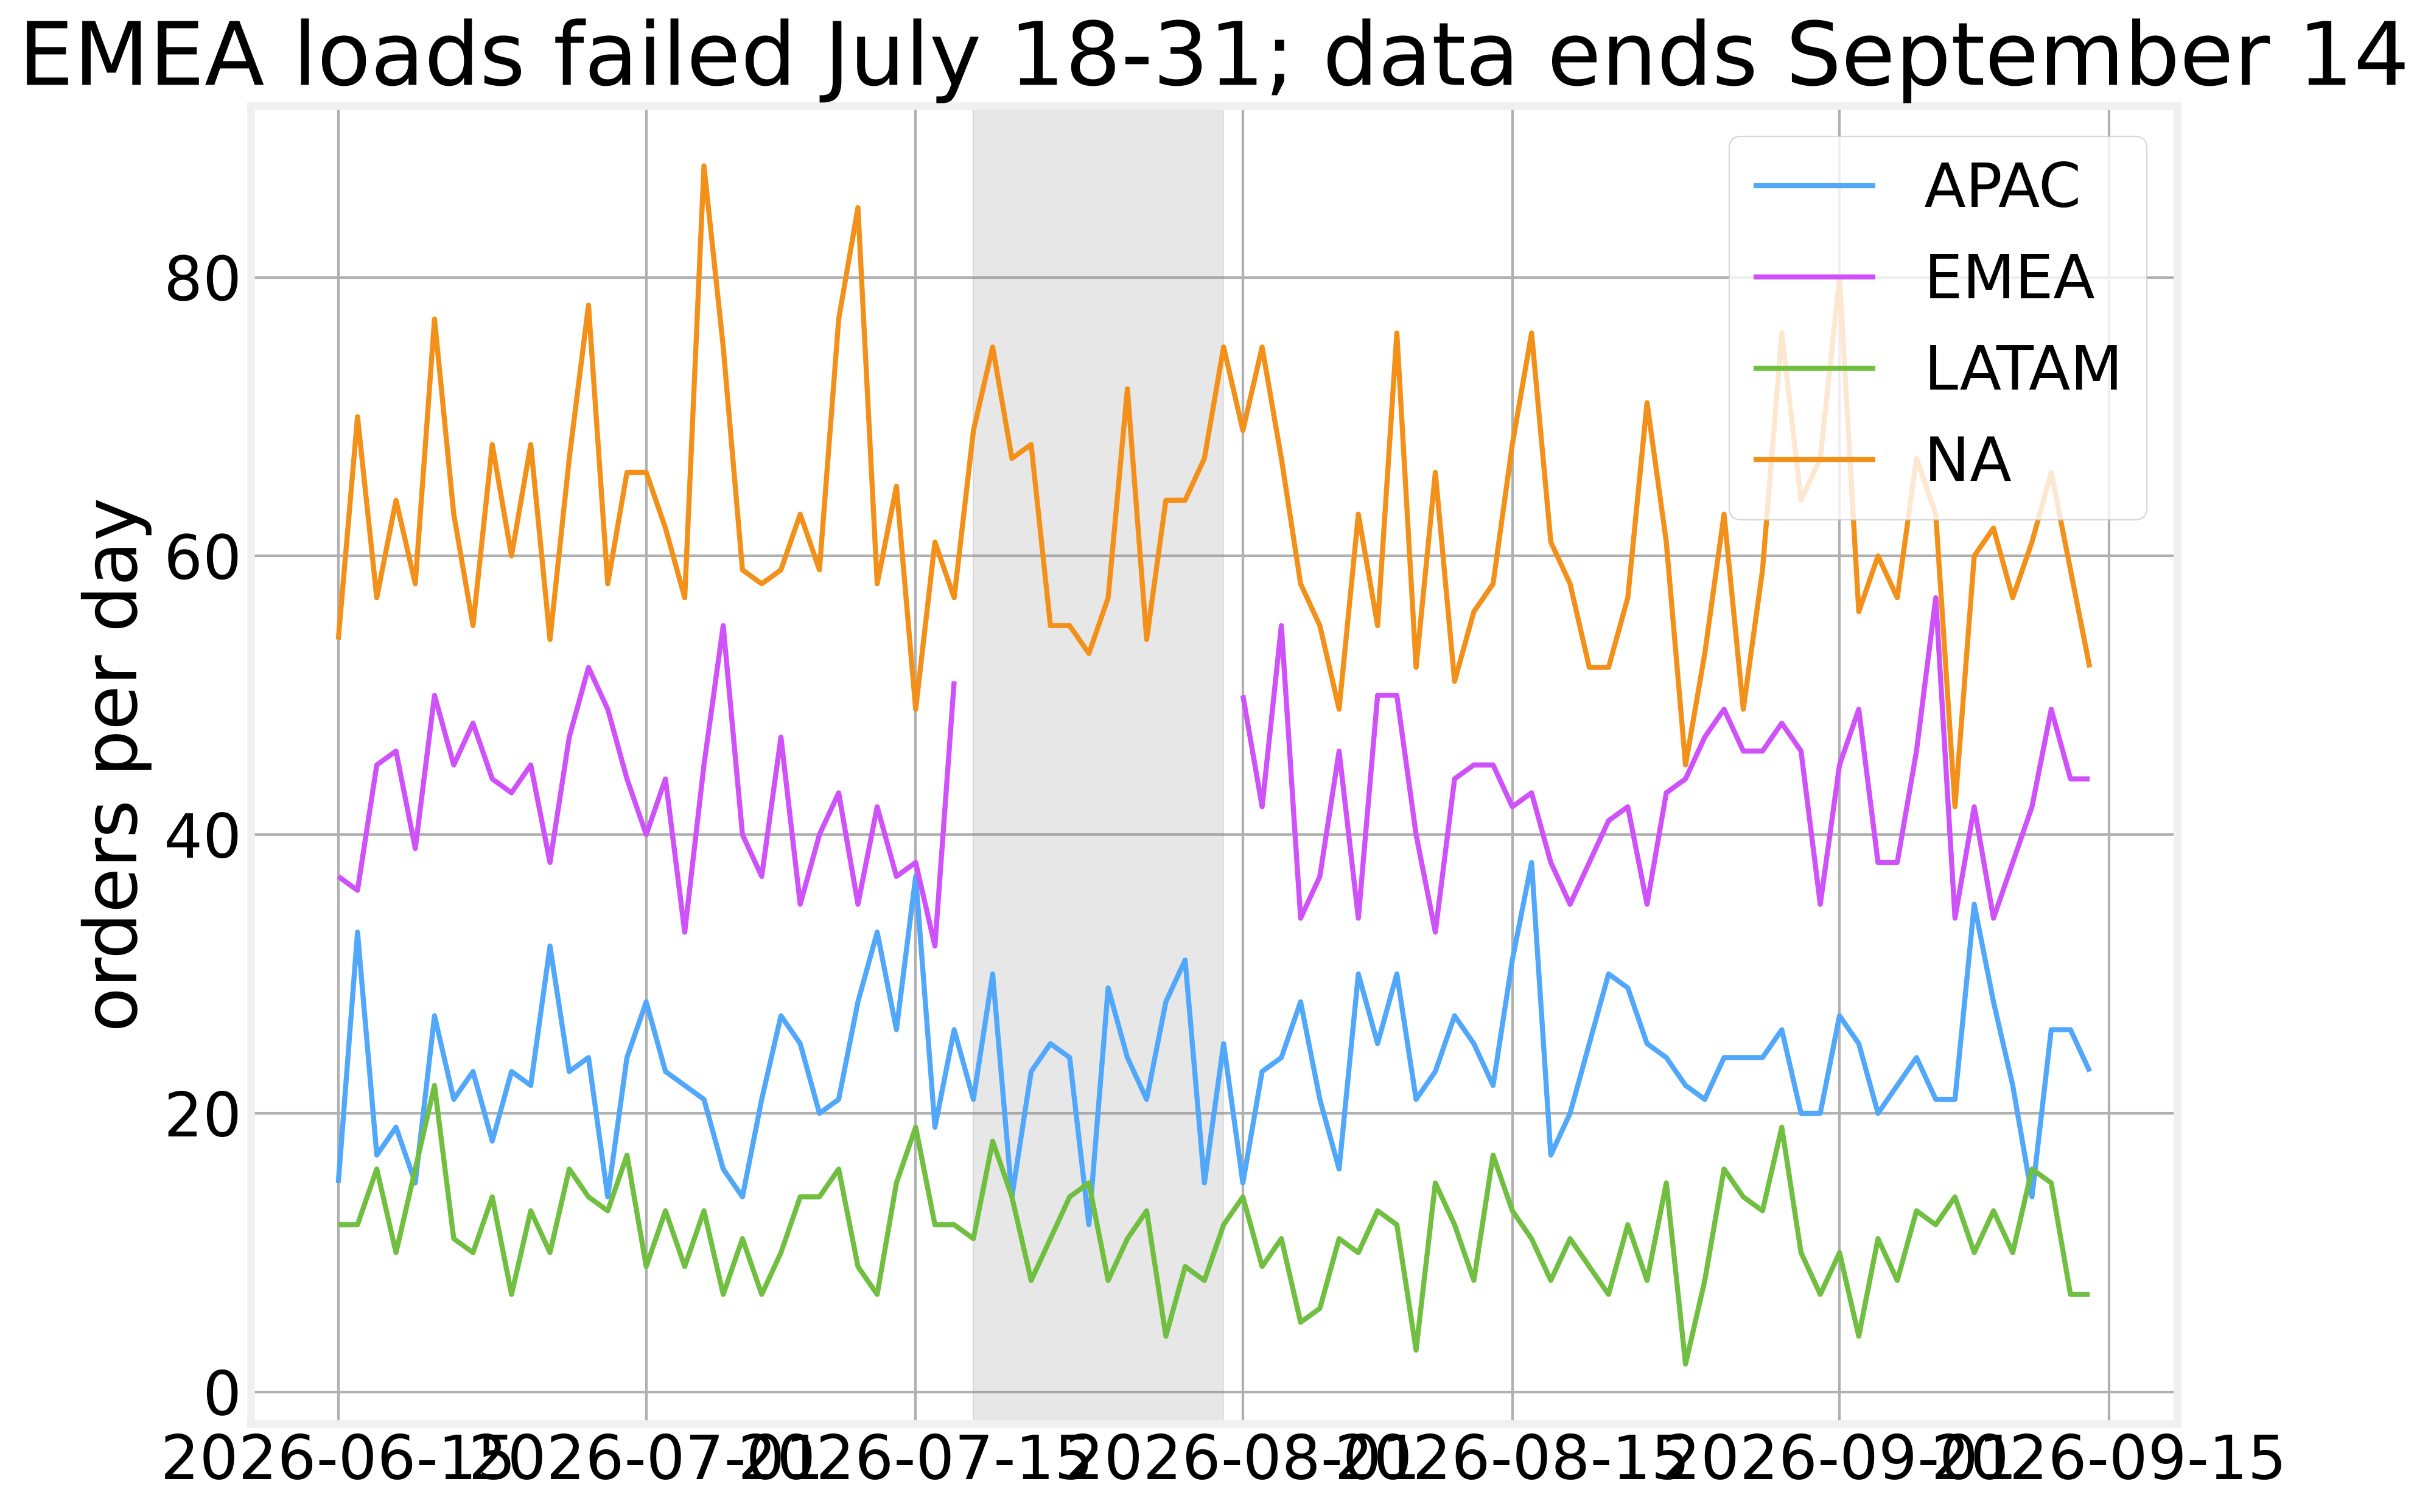

In [17]:
con = duckdb.connect(str(build_database()), read_only=True)
daily = con.sql("""SELECT order_date, region, COUNT(*) AS orders FROM orders
                   WHERE order_date >= DATE '2026-06-15' GROUP BY ALL ORDER BY order_date""").df()
pivot = daily.pivot(index="order_date", columns="region", values="orders")

fig, ax = plt.subplots()
for i, region in enumerate(pivot.columns):
    ax.plot(pivot.index, pivot[region], color=colors[i], label=region, lw=2)
ax.axvspan(pd.Timestamp("2026-07-18"), pd.Timestamp("2026-07-31"), color=colors[7], alpha=0.2)
ax.set_ylabel("orders per day")
ax.set_title("EMEA loads failed July 18-31; data ends September 14")
ax.legend();

In [18]:
for period, region in [("2026-06", "EMEA"), ("2026-07", "EMEA"), ("2026-07", None), ("2026-09", None)]:
    days, expected, failed = verifier.coverage(period, region)
    print(f"{period} {region or 'all':5}  {days:2}/{expected} days with data, {failed:2} failed loads")

2026-06 EMEA   30/30 days with data,  0 failed loads
2026-07 EMEA   17/31 days with data, 14 failed loads
2026-07 all    31/31 days with data, 14 failed loads
2026-09 all    14/30 days with data,  0 failed loads


# 4. Wiring it in

`VerifiedAnswer` is an `on_final` hook: it parses the report, verifies every claim and attaches the outcome to the answer the user sees.

In [19]:
%%writefile -a harness/verify.py


# --- wiring it in: an on_final hook --------------------------------------------------------

class VerifiedAnswer:
    """``on_final`` hook: verify the report and render the result for the user."""

    def __init__(self, verifier: Verifier):
        self.verifier = verifier
        self.last: Verification | None = None
        self.report: dict | None = None

    def __call__(self, text: str) -> str:
        try:
            self.report = parse_report(text)
        except ValueError as e:
            self.last = Verification([Check("report", "error", str(e))])
            return f"UNVERIFIED (could not parse report: {e})\n\n{text}"
        self.last = self.verifier.verify(self.report)
        failed = [c for c in self.last.checks if c.status != "verified"]
        lines = [self.report.get("summary", "")]
        if not self.last.checks:
            lines.append("\nVerification: the report makes no checkable claims.")
        elif failed:
            lines.append(f"\nVerification: {len(failed)} of {len(self.last.checks)} claims "
                         "did not pass:")
            lines += [f"  - [{c.status}] {c.claim}: {c.detail}" for c in failed]
        else:
            lines.append(f"\nVerification: all {len(self.last.checks)} claims re-derived.")
        return "\n".join(lines)

Appending to harness/verify.py


In [20]:
load("verify")
from harness.verify import VerifiedAnswer

verified = VerifiedAnswer(verifier)
agent = Agent(make_llm(context_window=10**6), toolbox, system_prompt=SYSTEM, on_final=verified)

for q in QUESTIONS.values():
    print("Q:", q)
    print(agent.run(q).answer)
    print("-" * 100)

Q: What was our monthly revenue in 2026?
Monthly revenue for 2026:
- 2026-01: $45,772,426
- 2026-02: $42,181,157
- 2026-03: $58,447,846
- 2026-04: $62,834,867
- 2026-05: $77,647,339
- 2026-06: $81,374,149
- 2026-07: $75,020,228
- 2026-08: $65,022,335
- 2026-09: $37,335,913

Revenue fell 43% in 2026-09 compared with 2026-08.

Verification: 10 of 10 claims did not pass:
  - [unit_error] Revenue in 2026-01: USD claim sums an *_cents column without /100
  - [unit_error] Revenue in 2026-02: USD claim sums an *_cents column without /100
  - [unit_error] Revenue in 2026-03: USD claim sums an *_cents column without /100
  - [unit_error] Revenue in 2026-04: USD claim sums an *_cents column without /100
  - [unit_error] Revenue in 2026-05: USD claim sums an *_cents column without /100
  - [unit_error] Revenue in 2026-06: USD claim sums an *_cents column without /100
  - [unit_error] Revenue in 2026-07: USD claim sums an *_cents column without /100
  - [unit_error] Revenue in 2026-08: USD claim s

In August we received 230 feedback comments with an average rating of 3.13. 23% of them mention checkout problems. Examples: "Website checkout crashed at the payment step. Ordered the Trekking Poles in store instead." | "Website checkout crashed at the payment step. Ordered the Gaiters in store instead."

Also worth noting: Q3 revenue grew 40%.

Verification: 1 of 3 claims did not pass:
  - [unsupported] Q3 revenue grew 40%: no query backs this claim
----------------------------------------------------------------------------------------------------
Q: What was EMEA revenue in July compared to June?


EMEA revenue was $14,222,708 in July versus $24,979,265 in June, a 43% decline.

Verification: 3 of 3 claims did not pass:
  - [unit_error] EMEA revenue in June: USD claim sums an *_cents column without /100
  - [unit_error] EMEA revenue in July: USD claim sums an *_cents column without /100
  - [incomplete_period] EMEA revenue change June -> July: 2026-07 for EMEA: data for 17/31 days, 14 failed loads
----------------------------------------------------------------------------------------------------


# 5. LLM-as-judge: only for what judges are good at

After the numbers are verified there is still a question code can't answer: **is this a good report?** Is the answer up front, is it readable, does it mention caveats? That's a job for a model acting as judge, using a rubric. Notice what the rubric explicitly excludes. `MockJudge` is a deterministic stand-in that follows the same rubric.

In [21]:
%%writefile -a harness/verify.py


# --- LLM-as-judge, for clarity and usefulness only --------------------------------------------

JUDGE_PROMPT = """You are reviewing a data report for a business reader.
The numbers have ALREADY been verified by re-running queries; do not assess correctness.
Score 1-5 for:
- clarity: is it easy to read, with the answer first and no unexplained jargon?
- usefulness: does it answer the question, quantify the effect, and note caveats?
Return JSON: {"clarity": n, "usefulness": n, "comments": "..."}"""


class MockJudge:
    """Deterministic stand-in for an LLM judge using the rubric above."""

    JARGON = ("strftime", "sum(", "amount_cents", "group by", "null", "sql")

    def score(self, question: str, summary: str, verification: Verification | None = None) -> dict:
        sentences = [s for s in summary.replace("\n", " ").split(". ") if s.strip()]
        avg_len = sum(len(s.split()) for s in sentences) / max(len(sentences), 1)
        clarity = 5 - (avg_len > 25) - (avg_len > 40) - any(j in summary.lower() for j in self.JARGON)
        has_numbers = any(ch.isdigit() for ch in summary)
        caveat = any(w in summary.lower() for w in ("incomplete", "missing", "partial", "caveat", "only"))
        on_topic = len(set(question.lower().split()) & set(summary.lower().split())) >= 2
        usefulness = 1 + has_numbers + caveat + on_topic + (verification is None or verification.passed)
        comments = []
        if not caveat:
            comments.append("no caveats about data quality")
        if avg_len > 25:
            comments.append("long sentences")
        return {"clarity": max(clarity, 1), "usefulness": usefulness,
                "comments": "; ".join(comments) or "clear and useful"}

Appending to harness/verify.py


In [22]:
load("verify")
from harness.verify import JUDGE_PROMPT, MockJudge

print(JUDGE_PROMPT)

You are reviewing a data report for a business reader.
The numbers have ALREADY been verified by re-running queries; do not assess correctness.
Score 1-5 for:
- clarity: is it easy to read, with the answer first and no unexplained jargon?
- usefulness: does it answer the question, quantify the effect, and note caveats?
Return JSON: {"clarity": n, "usefulness": n, "comments": "..."}


Why keep the judge away from correctness? Because judges score prose, and a fluent wrong report reads exactly like a fluent right one. Here is the judge scoring the careless "why did revenue drop" report, the one built on a made-up competitor, against the careful one:

In [23]:
judge = MockJudge()
rows = []
for label, llm in [("careless (fabricated cause)", make_llm(sloppy_units=False)),
                   ("careful (queried cause)", make_llm(careful=True))]:
    rep = parse_report(Agent(llm, toolbox, system_prompt=SYSTEM).run(QUESTIONS["drop"]).answer)
    statuses = [c.status for c in verifier.verify(rep).checks]
    rows.append({"report": label, **judge.score(QUESTIONS["drop"], rep["summary"]),
                 "unsupported claims": statuses.count("unsupported")})
pd.DataFrame(rows)

,report,clarity,usefulness,comments,unsupported claims
0,careless (fabricated cause),5,4,no caveats about data quality,1
1,careful (queried cause),5,4,no caveats about data quality,0


Read the prose alone and both reports look equally good. The fabricated cause is short, confident and specific, which is exactly what a style rubric rewards. Only verification tells them apart: the careless report rests on a claim with no query behind it. So we use judges for **clarity, usefulness and tone**, and code for **truth**.

# 6. The self-consistent lie

The verifier re-runs *the model's own SQL*. What if that SQL is wrong in a way that makes the claim agree with itself? Here a model computed NA's July-to-August change over **all** orders, including the failed ones, so the outage disappears:

In [24]:
sneaky = exercise_05_claims()[1]
print(sneaky["text"], "=", sneaky["value"], "%")
print(sneaky["sql"])
verifier.check({**sneaky, "period": None})

NA revenue change July -> August = -5.9 %
SELECT 100.0 * (a.r - b.r) / b.r AS pct_change FROM (SELECT SUM(amount_cents) AS r FROM orders WHERE region = 'NA' AND strftime(order_date, '%Y-%m') = '2026-08') a, (SELECT SUM(amount_cents) AS r FROM orders WHERE region = 'NA' AND strftime(order_date, '%Y-%m') = '2026-07') b


Check(claim='NA revenue change July -> August', status='verified', detail='', expected=-5.9, actual=-5.850832234735826)

It passes. The query really does return that number, so a value check can't see the problem: the *definition* of revenue is wrong. The fix is to stop trusting the model's SQL for the metrics that matter, and recompute them from a **canonical definition** owned by the harness. That's the exercise.

You now have a working `harness/verify.py`.

**Takeaways**
- Make claims machine-checkable: value, unit, period, query.
- Re-run every query, check units on the syntax tree, check coverage before comparing periods.
- A claim with no query behind it is a fabrication until proven otherwise.
- Recompute key metrics from canonical definitions instead of trusting model SQL.
- LLM judges grade prose. They don't grade facts.

# Exercise: recompute, don't re-run

*Estimated time: 10 minutes*

Write `recompute_change(claim)` for percent-change claims like the ones in `exercise_05_claims()`. Each claim has `value`, `region`, `new` and `old` periods (`YYYY-MM`).

1. Recompute revenue for both periods **yourself**, using the canonical definition: completed orders, `SUM(amount_cents) / 100.0`, filtered by region and month. Ignore the claim's `sql`.
2. If your percent change differs from `claim["value"]` by more than 0.1 points, return `"mismatch"`.
3. Otherwise, if either period is incomplete (`verifier.coverage(period, region)` returns `(days, expected, failed)`), return `"incomplete_period"`.
4. Otherwise return `"verified"`.

Use `run_sql(sql)`, which returns `(columns, rows)` through the SQL guard.

In [25]:
for c in exercise_05_claims():
    print(c["text"], c["value"])

def recompute_change(claim):
    # YOUR CODE HERE
    return "verified"

NA revenue change April -> May 21.4
NA revenue change July -> August -5.9
EMEA revenue change June -> July -43.1


In [26]:
check_05(recompute_change)

PASS  NA revenue change April -> May
FAIL  NA revenue change July -> August  (expected 'mismatch', got 'verified')
FAIL  EMEA revenue change June -> July  (expected 'incomplete_period', got 'verified')

Not there yet; keep going.


<details>
<summary><b>Show solution</b></summary>

```python
# Solution: recompute a percent change from the canonical revenue definition,
# ignoring the model's own SQL, and check both periods are complete.
import math

from harness.guardrails import ALLOWED_TABLES
from harness.exercises import check_05
from harness.mcp_client import MCPClient
from harness.verify import Verifier, make_sql_runner

client = MCPClient().start()
run_sql = make_sql_runner(client, ALLOWED_TABLES)
verifier = Verifier(run_sql)


def canonical_revenue(month, region=None):
    where = f" AND region = '{region}'" if region else ""
    _, rows = run_sql(f"""SELECT SUM(amount_cents) / 100.0 AS revenue FROM orders
                          WHERE status = 'completed'{where}
                            AND strftime(order_date, '%Y-%m') = '{month}'""")
    return float(rows[0][0])


def recompute_change(claim):
    region = claim.get("region")
    new, old = canonical_revenue(claim["new"], region), canonical_revenue(claim["old"], region)
    actual = 100 * (new - old) / old
    if not math.isclose(claim["value"], actual, abs_tol=0.1):
        return "mismatch"
    for period in (claim["new"], claim["old"]):
        days, expected, failed = verifier.coverage(period, region)
        if days < expected or failed:
            return "incomplete_period"
    return "verified"


check_05(recompute_change)
client.close()
```

You can also load it into a new cell with `%load solutions/05_recompute_change.py`.

</details>

In [27]:
client.close()

<center>
     <img src="data/D4Sci_logo_full.png" alt="Data For Science, Inc" align="center" border="0" width=300px>
</center>